# Lost in Terminology: What BLEU Misses in English→Turkish Technical Translation

Compares OPUS-MT and NLLB-200 on general text (FLORES-200) and on a technical text (my thesis translation of Green, Heer & Manning, CHI 2013). See the README for results and discussion.

Run on Google Colab with a T4 GPU.

## 1. Setup

In [16]:
!pip install -q sacrebleu sentencepiece

## 2. Load FLORES-200 (first 200 sentences of `devtest`)

In [17]:
!wget -q https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz
!tar -xzf flores200_dataset.tar.gz

def read_lines(path):
    with open(path, encoding="utf-8") as f:
        return [line.strip() for line in f]

english = read_lines("flores200_dataset/devtest/eng_Latn.devtest")
turkish = read_lines("flores200_dataset/devtest/tur_Latn.devtest")

N = 200
english = english[:N]
turkish = turkish[:N]

print(len(english), "sentences")
print("EN:", english[0])
print("TR:", turkish[0])


200 sentences
EN: "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
TR: Daha önce diyabetik olup şimdi diyabetik olmayan 4 aylık farelerimiz var, diye ekledi.


## 3. OPUS-MT
Load the model and translate the 200 sentences in batches of 16.

In [18]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

opus_name = "Helsinki-NLP/opus-mt-tc-big-en-tr"
opus_tokenizer = AutoTokenizer.from_pretrained(opus_name)
opus_model = AutoModelForSeq2SeqLM.from_pretrained(opus_name).to("cuda")

def translate_opus(sentences):
    inputs = opus_tokenizer(sentences, return_tensors="pt", padding=True, truncation=True).to("cuda")
    outputs = opus_model.generate(**inputs, max_new_tokens=256)
    return opus_tokenizer.batch_decode(outputs, skip_special_tokens=True)

print(translate_opus([english[0]]))


/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


['"Artık diyabetik olmayan ve eskiden diyabetik olan 4 aylık farelerimiz var" diye ekledi.']


In [19]:
opus_tr = []

for i in range(0, len(english), 16):
    batch = english[i:i+16]
    opus_tr += translate_opus(batch)

print(len(opus_tr), "translations")

for i in range(3):
    print("EN:  ", english[i])
    print("REF: ", turkish[i])
    print("OPUS:", opus_tr[i])
    print()

200 translations
EN:   "We now have 4-month-old mice that are non-diabetic that used to be diabetic," he added.
REF:  Daha önce diyabetik olup şimdi diyabetik olmayan 4 aylık farelerimiz var, diye ekledi.
OPUS: "Artık diyabetik olmayan ve eskiden diyabetik olan 4 aylık farelerimiz var" diye ekledi.

EN:   Dr. Ehud Ur, professor of medicine at Dalhousie University in Halifax, Nova Scotia and chair of the clinical and scientific division of the Canadian Diabetes Association cautioned that the research is still in its early days.
REF:  Halifax, Nova Scotia'daki Dalhousie Üniversitesi'nde tıp profesörü ve Kanada Diyabet Derneği'nin klinik ve bilim alanı başkanı olan Dr. Ehud Ur, çalışmanın henüz başlangıç aşamasında olduğu konusunda uyarıda bulundu.
OPUS: Halifax, Nova Scotia'daki Dalhousie Üniversitesi'nde tıp profesörü ve Kanada Diyabet Derneği'nin klinik ve bilimsel bölümünün başkanı Dr. Ehud Ur, araştırmanın hala ilk günlerinde olduğu konusunda uyardı.

EN:   Like some other experts, h

### Scores

In [20]:
import sacrebleu

opus_bleu = sacrebleu.corpus_bleu(opus_tr, [turkish])
opus_chrf = sacrebleu.corpus_chrf(opus_tr, [turkish])

print("OPUS-MT  BLEU:", round(opus_bleu.score, 1), " chrF:", round(opus_chrf.score, 1))

OPUS-MT  BLEU: 31.1  chrF: 62.0


## 4. NLLB-200 (distilled 600M)
NLLB is multilingual, so the source language (`eng_Latn`) and the target language (`tur_Latn`) must be set explicitly.

In [23]:
nllb_name = "facebook/nllb-200-distilled-600M"
nllb_tokenizer = AutoTokenizer.from_pretrained(nllb_name, src_lang="eng_Latn")
nllb_model = AutoModelForSeq2SeqLM.from_pretrained(nllb_name).to("cuda")

def translate_nllb(sentences):
    inputs = nllb_tokenizer(sentences, return_tensors="pt", padding=True, truncation=True).to("cuda")
    outputs = nllb_model.generate(
        **inputs,
        forced_bos_token_id=nllb_tokenizer.convert_tokens_to_ids("tur_Latn"),
        max_new_tokens=256,
    )
    return nllb_tokenizer.batch_decode(outputs, skip_special_tokens=True)

print(translate_nllb([english[0]]))

['"Şimdi diyabetik olmayan, 4 aylık farelerimiz var ve eskiden diyabetiklerdi", diye ekledi.']


In [24]:
nllb_tr = []

for i in range(0, len(english), 16):
    batch = english[i:i+16]
    nllb_tr += translate_nllb(batch)

### Scores

In [25]:
nllb_bleu = sacrebleu.corpus_bleu(nllb_tr, [turkish])
nllb_chrf = sacrebleu.corpus_chrf(nllb_tr, [turkish])

print("OPUS-MT  BLEU:", round(opus_bleu.score, 1), " chrF:", round(opus_chrf.score, 1))
print("NLLB     BLEU:", round(nllb_bleu.score, 1), " chrF:", round(nllb_chrf.score, 1))

OPUS-MT  BLEU: 31.1  chrF: 62.0
NLLB     BLEU: 21.5  chrF: 55.3


### Save the FLORES translations

In [26]:
import pandas as pd

results = pd.DataFrame({
    "source": english,
    "reference": turkish,
    "opus": opus_tr,
    "nllb": nllb_tr,
})

results.to_excel("flores_translations.xlsx", index=False)
results.head()

,source,reference,opus,nllb
0,"""We now have 4-month-old mice that are non-dia...",Daha önce diyabetik olup şimdi diyabetik olmay...,"""Artık diyabetik olmayan ve eskiden diyabetik ...","""Şimdi diyabetik olmayan, 4 aylık farelerimiz ..."
1,"Dr. Ehud Ur, professor of medicine at Dalhousi...","Halifax, Nova Scotia'daki Dalhousie Üniversite...","Halifax, Nova Scotia'daki Dalhousie Üniversite...",Halifax'taki Dalhousie Üniversitesi'nde tıp pr...
2,"Like some other experts, he is skeptical about...","Bazı diğer uzmanlar gibi o da, bu bulguların z...","Diğer bazı uzmanlar gibi, diyabetin tedavi edi...","Bazı uzmanlar gibi, diyabetin iyileştirilebili..."
3,"On Monday, Sara Danius, permanent secretary of...",İsveç Akademisi Nobel Edebiyat Komitesi'nin da...,"Pazartesi günü, İsveç Akademisi'ndeki Nobel Ed...",Pazartesi günü İsveç Akademisi'nde Edebiyat iç...
4,"Danius said, ""Right now we are doing nothing. ...","Danius dedi ki, ""Şu anda hiçbir şey yapmıyoruz...","Danius, ""Şu anda hiçbir şey yapmıyoruz. En yak...","Danius, ""Şu anda hiçbir şey yapmıyoruz. En yak..."


## 5. Technical text: my thesis translation
76 sentence pairs from the Abstract, Introduction and Related Work sections.

In [29]:
import pandas as pd
# The thesis data is not included in this repository (copyright).
# Upload any sentence-aligned Excel file with 'en' and 'tr' columns:
# from google.colab import files; files.upload()

thesis = pd.read_excel("thesis_sentences.xlsx")
thesis_en = thesis["en"].tolist()
thesis_tr = thesis["tr"].tolist()

print(len(thesis_en), "sentence pairs")

Saving thesis_sentences.xlsx to thesis_sentences.xlsx
76 sentence pairs


In [30]:
def translate_all(sentences, translate_fn, batch_size=16):
    output = []
    for i in range(0, len(sentences), batch_size):
        output += translate_fn(sentences[i:i+batch_size])
    return output

thesis_opus = translate_all(thesis_en, translate_opus)
thesis_nllb = translate_all(thesis_en, translate_nllb)

print(thesis_opus[0])
print(thesis_nllb[0])

Dil çevirisi yavaş ve pahalıdır, bu nedenle çeşitli makine yardımı türleri tasarlanmıştır.
Dil tercümanı yavaş ve pahalı, bu nedenle çeşitli makine yardımları tasarlandı.


### Scores on both datasets

In [31]:
def score(hyp, ref):
    bleu = sacrebleu.corpus_bleu(hyp, [ref]).score
    chrf = sacrebleu.corpus_chrf(hyp, [ref]).score
    return round(bleu, 1), round(chrf, 1)

print("                  BLEU  chrF")
print("FLORES  OPUS-MT ", score(opus_tr, turkish))
print("FLORES  NLLB    ", score(nllb_tr, turkish))
print("Thesis  OPUS-MT ", score(thesis_opus, thesis_tr))
print("Thesis  NLLB    ", score(thesis_nllb, thesis_tr))

                  BLEU  chrF
FLORES  OPUS-MT  (31.1, 62.0)
FLORES  NLLB     (21.5, 55.3)
Thesis  OPUS-MT  (32.7, 60.0)
Thesis  NLLB     (23.5, 53.5)


## 6. Terminology check
Accepted Turkish equivalents are written as **stems** so that suffixed forms also match (e.g. `kaynak met` matches *kaynak metin* and *kaynak metnin*, `tasla` matches *taslak* and *taslağın*). `tr_lower` handles the Turkish I/ı and İ/i.

In [32]:
terms = {
    "post-edit":                         ["sonradan düzenle"],
    "machine translation|\\bMT\\b":      ["makine çeviri"],
    "unaided":                           ["yardımsız", "yardım almadan"],
    "gisting":                           ["gisting", "genel bir fikir", "anlama aşama"],
    "drafting|draft":                    ["tasla"],
    "revision":                          ["revizyon"],
    "cognitive load|cognitive burden":   ["bilişsel yük"],
    "source text":                       ["kaynak met"],
    "target text":                       ["hedef met"],
    "parts? of speech":                  ["sözcük tür"],
    "eye track":                         ["göz izle"],
    "bilingual":                         ["iki dilli", "ikidilli"],
    "monolingual":                       ["tek dilli", "tekdilli"],
    "collaborative translation":         ["işbirlik"],
    "Think Aloud Protocol":              ["sesli düşünme", "yüksek sesle düşünme"],
    "translation workbench":             ["çeviri çalışma ortam", "çeviri iş tezgâh"],
    "type II error":                     ["tür hata", "tip ii hata"],
    "fixed effect":                      ["sabit etki"],
    "pupil dilation":                    ["göz bebeği genişle"],
}

In [33]:
import re

def tr_lower(text):
    return text.replace("I", "ı").replace("İ", "i").lower()

def term_accuracy(translations):
    correct, total = 0, 0
    for en_sentence, tr_sentence in zip(thesis_en, translations):
        for en_term, tr_options in terms.items():
            if re.search(en_term, en_sentence, flags=re.IGNORECASE):
                total += 1
                if any(option in tr_lower(tr_sentence) for option in tr_options):
                    correct += 1
    return correct, total, round(100 * correct / total, 1)

print("Human (my thesis)", term_accuracy(thesis_tr))
print("OPUS-MT          ", term_accuracy(thesis_opus))
print("NLLB             ", term_accuracy(thesis_nllb))

Human (my thesis) (71, 78, 91.0)
OPUS-MT           (35, 78, 44.9)
NLLB              (29, 78, 37.2)


## 7. Chart

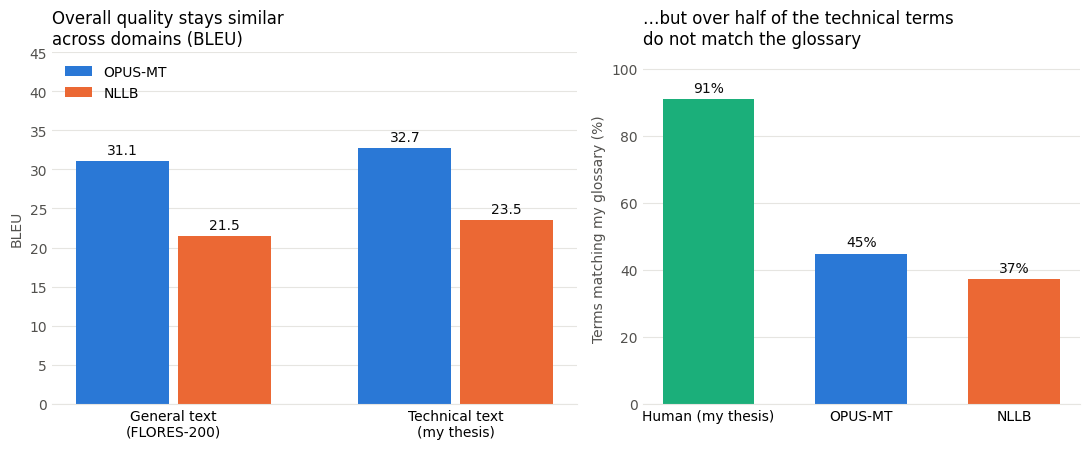

In [35]:
import matplotlib.pyplot as plt

# 1. Collect the numbers from the functions above (no hard-coded values)
bleu = {
    "OPUS-MT": [score(opus_tr, turkish)[0], score(thesis_opus, thesis_tr)[0]],
    "NLLB":    [score(nllb_tr, turkish)[0], score(thesis_nllb, thesis_tr)[0]],
}
terms_result = {
    "Human (my thesis)": term_accuracy(thesis_tr)[2],
    "OPUS-MT":           term_accuracy(thesis_opus)[2],
    "NLLB":              term_accuracy(thesis_nllb)[2],
}

# 2. Colours: each model keeps the same colour in both panels
colors = {"OPUS-MT": "#2a78d6", "NLLB": "#eb6834", "Human (my thesis)": "#1baf7a"}
ink, muted, grid = "#0b0b0b", "#52514e", "#e6e5e1"

# 3. Two panels side by side
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})

# 4. Left panel: BLEU
datasets = ["General text\n(FLORES-200)", "Technical text\n(my thesis)"]
width = 0.36
for k, (model, values) in enumerate(bleu.items()):
    xs = [i + (k - 0.5) * width for i in range(len(datasets))]
    bars = left.bar(xs, values, width=width - 0.03, color=colors[model], label=model)
    left.bar_label(bars, fmt="%.1f", padding=3, color=ink, fontsize=10)
left.set_xticks(range(len(datasets)), datasets)
left.set_ylim(0, 45)
left.set_ylabel("BLEU", color=muted)
left.set_title("Overall quality stays similar\nacross domains (BLEU)", loc="left", fontsize=12)
left.legend(frameon=False, loc="upper left")

# 5. Right panel: term accuracy
names = list(terms_result)
bars = right.bar(names, list(terms_result.values()), width=0.6, color=[colors[n] for n in names])
right.bar_label(bars, fmt="%.0f%%", padding=3, color=ink, fontsize=10)
right.set_ylim(0, 105)
right.set_ylabel("Terms matching my glossary (%)", color=muted)
right.set_title("…but over half of the technical terms\ndo not match the glossary", loc="left", fontsize=12)

# 6. Clean look: remove extra lines, lighten the grid
for ax in (left, right):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(grid)
    ax.yaxis.grid(True, color=grid, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", colors=muted, length=0)
    ax.tick_params(axis="x", length=0)

# 7. Save and show
fig.tight_layout()
fig.savefig("results_chart.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## 8. Export the non-matching cases for manual review
Each case was then labelled by hand: D = different but correct, E = left in English, Y = wrong, A = omitted. Results are in the README.

In [37]:
review = []

for i, (en, opus, nllb) in enumerate(zip(thesis_en, thesis_opus, thesis_nllb)):
    for en_term, tr_options in terms.items():
        if re.search(en_term, en, flags=re.IGNORECASE):
            for model, output in [("OPUS-MT", opus), ("NLLB", nllb)]:
                if not any(option in tr_lower(output) for option in tr_options):
                    review.append({
                        "row": i + 1,
                        "term": en_term,
                        "model": model,
                        "source": en,
                        "translation": output,
                        "verdict": "",
                    })

review = pd.DataFrame(review)
print(len(review), "cases to check")

review.to_excel("term_review.xlsx", index=False)

92 cases to check


## 9. Why is BLEU not lower on the technical text?
Recompute BLEU without citations and numbers (and without names/acronyms copied from the source), estimate 95% bootstrap confidence intervals, and compare how closely each reference follows the source length.

In [ ]:
import numpy as np

def strip_numbers(s):
    s = re.sub(r"\[[\d,\s]+\]", " ", s)        # citations like [46, 20]
    s = re.sub(r"[%\d][\d.,%'’-]*", " ", s)      # numbers, percentages, years
    return re.sub(r"\s+", " ", s).strip()

def strip_copied(s, src):
    # also remove names and acronyms that appear unchanged in the English source
    copied = {w for w in re.findall(r"\b\w+\b", src) if w[0].isupper() or w[0].isdigit()}
    words = [w for w in strip_numbers(s).split() if re.split(r"[’'`]", w.strip(".,;:!?()\"“”"))[0] not in copied]
    return " ".join(words)

def bootstrap_ci(hyp, ref, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(n):
        idx = rng.choice(len(hyp), len(hyp))
        scores.append(sacrebleu.corpus_bleu([hyp[i] for i in idx], [[ref[i] for i in idx]]).score)
    return np.percentile(scores, [2.5, 97.5]).round(1)

for name, src, hyp, ref in [("FLORES OPUS-MT", english, opus_tr, turkish), ("FLORES NLLB", english, nllb_tr, turkish),
                            ("Thesis OPUS-MT", thesis_en, thesis_opus, thesis_tr), ("Thesis NLLB", thesis_en, thesis_nllb, thesis_tr)]:
    no_num = sacrebleu.corpus_bleu([strip_numbers(h) for h in hyp], [[strip_numbers(r) for r in ref]]).score
    no_copy = sacrebleu.corpus_bleu([strip_copied(h, s) for h, s in zip(hyp, src)], [[strip_copied(r, s) for r, s in zip(ref, src)]]).score
    print(f"{name}: BLEU {score(hyp, ref)[0]} | without citations/numbers {no_num:.1f} | also without names {no_copy:.1f} | 95% CI {bootstrap_ci(hyp, ref)}")

print("Average words (source -> reference): thesis", round(np.mean([len(s.split()) for s in thesis_en]), 1), "->", round(np.mean([len(s.split()) for s in thesis_tr]), 1),
      "| FLORES", round(np.mean([len(s.split()) for s in english]), 1), "->", round(np.mean([len(s.split()) for s in turkish]), 1))
